# Lab 3 - Millions of TVs, Who Is Watching?
Name: Oleksandr Serpovych Liubomyrovych | Group: KM-41

## Setup

In [45]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

## Task 1.1 - Five questions

**Answer:**

| Question | `acr_sessions` (Smart-TV ACR feed) | `viewings` (Lab 1 panel) |
| :--- | :--- | :--- |
| Grain | One continuous viewing session on one smart TV (ends when network, program, or input changes). | One viewing session by one panelist (`R`, `L`, `S`) or household (`H`) on one of the 10 networks. |
| Key | Smart TV device (`tv_id`) and hashed household IP (`hashed_ip`); no person-level ID. | Household or individual respondent (`respondent_id` with `resp_type` H, R, L, or S). |
| Coverage | 29,940 opted-in smart TVs (one set per home) over 14 broadcast days (Oct 14–27, 2024) across all inputs and recognized US networks; misses other sets in the home, people in the room, and unrecognized content (`app`/`unknown`). | ~4,000 probability-sampled households (~10,000 panelists) over 28 broadcast days (Oct 1–28, 2024) on 10 national networks; misses non-panel networks and streaming/non-linear inputs. |
| Weight | Unweighted convenience footprint (every opted-in TV counts equally as 1; no projection weights). | Calibrated daily weights (`weight`) projecting sample rows to all 125.8M US TV households and 317.3M P2+ persons. |
| Provenance | Simulated smart-TV ACR feed (modeled on LG Ad Solutions), collected via screen fingerprinting from opted-in retail smart TVs. | Simulated people-meter panel (modeled on Nielsen AMRLD), calibrated to published currency ratings. |

Biggest difference: The most consequential difference is Weight / Representativeness (alongside Key: devices vs. people) — `viewings` comes from a probability panel weighted to represent the entire US population of households and people, whereas `acr_sessions` is an unweighted convenience sample of opted-in devices from a single manufacturer that neither observes who is watching nor represents all US homes without statistical adjustment.

## Task 1.2 - Size and shape

In [46]:
# Convert start_utc and end_utc to US Eastern (tz-naive to match Lab 1 tables)
acr = acr_sessions.copy()
start_utc = pd.to_datetime(acr['start_utc'])
end_utc = pd.to_datetime(acr['end_utc'])
if start_utc.dt.tz is None:
    start_utc = start_utc.dt.tz_localize('UTC')
    end_utc = end_utc.dt.tz_localize('UTC')

acr['start_et'] = start_utc.dt.tz_convert('America/New_York').dt.tz_localize(None)
acr['end_et'] = end_utc.dt.tz_convert('America/New_York').dt.tz_localize(None)

# Broadcast day runs 06:00-05:59 Eastern
acr['broadcast_date'] = (acr['start_et'] - pd.Timedelta(hours=6)).dt.strftime('%Y-%m-%d')
acr['duration_sec'] = (acr['end_et'] - acr['start_et']).dt.total_seconds()
acr['duration_hr'] = acr['duration_sec'] / 3600.0

# Edit rule: drop every session shorter than 1 minute (< 60 seconds)
acr_clean = acr[acr['duration_sec'] >= 60].copy()

num_tvs = int(acr['tv_id'].nunique())
num_sessions = int(len(acr))
num_bcast_days = int(acr['broadcast_date'].nunique())

# In-tab: TV has at least one session (any type) on a broadcast day after edit rule
intab_tv_days_clean = acr_clean.groupby('broadcast_date')['tv_id'].nunique()
total_intab_tv_days = int(intab_tv_days_clean.sum())
avg_tvs_intab_per_day = round(intab_tv_days_clean.mean(), 1)

# Hours per in-tab TV per day (all session hours / in-tab TV-days), before and after edit rule
intab_tv_days_raw = int(acr.groupby('broadcast_date')['tv_id'].nunique().sum())
hours_per_tv_day_raw = round(acr['duration_hr'].sum() / total_intab_tv_days, 2)
hours_per_tv_day_clean = round(acr_clean['duration_hr'].sum() / total_intab_tv_days, 2)
share_sessions_dropped = round(1.0 - (len(acr_clean) / len(acr)), 3)

print("TVs:", num_tvs)
print("Sessions:", num_sessions)
print("Broadcast days:", num_bcast_days)
print("Average TVs in-tab per day:", f"{avg_tvs_intab_per_day:.1f}")
print("Hours per TV per day, raw:", f"{hours_per_tv_day_raw:.2f}")
print("Hours per TV per day, after edit rule:", f"{hours_per_tv_day_clean:.2f}")
print("Share of sessions dropped:", f"{share_sessions_dropped:.3f}")

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074.1
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.70
Share of sessions dropped: 0.299


## Task 1.3 - What the TV could not see

In [47]:
total_clean_hours = acr_clean['duration_hr'].sum()

by_session_type = (
    acr_clean.groupby('session_type')['duration_hr']
    .sum()
    .reset_index(name='hours')
    .sort_values('hours', ascending=False)
    .reset_index(drop=True)
)
by_session_type['share_of_hours'] = (by_session_type['hours'] / total_clean_hours).round(3)
by_session_type['hours'] = by_session_type['hours'].round(2)

by_input_source = (
    acr_clean.groupby('input_source')['duration_hr']
    .sum()
    .reset_index(name='hours')
    .sort_values('hours', ascending=False)
    .reset_index(drop=True)
)
by_input_source['share_of_hours'] = (by_input_source['hours'] / total_clean_hours).round(3)
by_input_source['hours'] = by_input_source['hours'].round(2)

# table: share of hours by session_type and by input_source
display(by_session_type)
display(by_input_source)

unknown_hours = acr_clean.loc[acr_clean['session_type'] == 'unknown', 'duration_hr'].sum()
share_unknown_pct = round((unknown_hours / total_clean_hours) * 100.0, 1)
print("Share of TV-on hours unknown (%):", share_unknown_pct)

,session_type,hours,share_of_hours
0,unknown,758616.58,0.396
1,live,615334.95,0.322
2,app,491827.37,0.257
3,dvr,47922.09,0.025


,input_source,hours,share_of_hours
0,built_in_app,588337.63,0.307
1,cable_box,527256.86,0.276
2,streaming_device,441584.39,0.231
3,antenna,165030.96,0.086
4,satellite_box,145356.64,0.076
5,game_or_disc,46134.51,0.024


Share of TV-on hours unknown (%): 39.6


**Answer:** In this synthetic dataset, 39.6% (`0.396` share) of post-edit "TV on" hours are logged as `unknown` (plus another 25.7% as `app` with no network code, leaving only 32.2% as recognized `live` and 2.5% as `dvr`). A real commercial ACR feed (such as LG Ad Solutions' sample with 66% unknown hours) typically has an even higher share of `unknown` hours because real-world fingerprint libraries cannot cover every local station, regional feed, multicast/FAST channel, or niche cable network, and real screen captures suffer from hardware/firmware blocks (such as HDCP/DRM restrictions), network latency, or noisy visual/audio fingerprints during menus, screen savers, and time-shifted playback.

Two kinds of viewing that end up as `unknown`:
1. Gaming consoles and physical disc players (`game_or_disc`, 2.4% of hours) or PC/HDMI screen casting: Video games, Blu-ray/DVD movies, and home media displayed on the glass do not exist in a linear TV broadcast fingerprint library, so the TV logs the screen as on (`unknown`) without a network match.
2. Unfingerprinted streaming content and blocked apps (via `streaming_device` or `built_in_app`), or time-shifted viewing beyond the reference window: When viewers watch SVOD/AVOD content on an external Roku/Fire TV/Apple TV stick or a native app that blocks ACR or lacks reference fingerprints (as well as local/syndicated programming or older DVR recordings not in the live fingerprint database), ACR cannot match the screen and records the session as `unknown`.

## Task 2.1 - Match

In [48]:
# Unique TVs and their hashed_ip
tv_ips = acr[['tv_id', 'hashed_ip']].drop_duplicates()

# Count how many households in hh_attributes share each hashed_ip
ip_hh_counts = hh_attributes.groupby('hashed_ip')['household_id'].nunique()
tv_ips['hh_matches'] = tv_ips['hashed_ip'].map(ip_hh_counts).fillna(0).astype(int)

matched_one_pct = round((tv_ips['hh_matches'] == 1).mean() * 100.0, 1)
shared_ip_pct = round((tv_ips['hh_matches'] > 1).mean() * 100.0, 1)
not_matched_pct = round((tv_ips['hh_matches'] == 0).mean() * 100.0, 1)

print("Matched to one household (%):", matched_one_pct)
print("Shared IP, unresolved (%):", shared_ip_pct)
print("Not matched (%):", not_matched_pct)

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:** An IP address is a weak linkage key because it identifies a network connection rather than a permanent household: ISPs dynamically reassign residential IP addresses over time (causing churn and staleness in compiled IP-to-home graphs), multiple households in apartment buildings or multi-dwelling units often share a single router/NAT or carrier-grade IP (creating unresolved 1-to-many collisions), and VPNs, mobile hotspots, or privacy relays obscure the true physical household completely.

## Task 2.2 - Profile

In [49]:
# Matched TVs (exactly 1 household match)
single_match_hh = hh_attributes[
    hh_attributes['hashed_ip'].isin(ip_hh_counts[ip_hh_counts == 1].index)
].copy()
matched_tvs = tv_ips[tv_ips['hh_matches'] == 1].merge(
    single_match_hh, on='hashed_ip', how='left'
)

def map_income_3groups(val):
    s = str(val).strip()
    if any(k in s for k in ['Under $25', '$25', '25k-49k', '25-49', '<$25', 'Under $50', '<50']):
        return 'Under $50k'
    elif any(k in s for k in ['$50', '$75', '50k-74k', '75k-99k', '50-74', '75-99', '50-100']):
        return '$50-100k'
    elif any(k in s for k in ['$100', '$150', '100k', '150k']):
        return '$100k+'
    return s

matched_tvs['income_3'] = matched_tvs['income_band'].apply(map_income_3groups)

# Panel households (H records) in Oct 14-27, 2024 with average weight over in-tab days
dw_temp = daily_weights.copy()
dw_temp['b_date'] = pd.to_datetime(dw_temp['broadcast_date']).dt.strftime('%Y-%m-%d')
dw_oct14_27 = dw_temp[
    (dw_temp['b_date'] >= '2024-10-14') & (dw_temp['b_date'] <= '2024-10-27')
].copy()

if 'resp_type' in dw_oct14_27.columns:
    panel_hh_weights = dw_oct14_27[dw_oct14_27['resp_type'] == 'H'].groupby('respondent_id')['weight'].mean().reset_index()
else:
    h_ids = set(viewings.loc[viewings['resp_type'] == 'H', 'respondent_id'])
    panel_hh_weights = dw_oct14_27[dw_oct14_27['respondent_id'].isin(h_ids)].groupby('respondent_id')['weight'].mean().reset_index()

# Join panel households to viewer_attributes + attributes
va_merged = viewer_attributes.merge(attributes, on='attr_id', how='left')
name_col = [c for c in attributes.columns if 'name' in c.lower() or 'desc' in c.lower() or 'label' in c.lower() or 'val' in c.lower()]
group_col = [c for c in attributes.columns if 'group' in c.lower() or 'cat' in c.lower() or 'type' in c.lower()]
attr_label_col = name_col[0] if name_col else [c for c in attributes.columns if c != 'attr_id'][-1]
attr_group_col = group_col[0] if group_col else [c for c in attributes.columns if c != 'attr_id'][0]

# Extract region and income for panel households
va_hh = va_merged[va_merged['respondent_id'].isin(panel_hh_weights['respondent_id'])].copy()
va_hh['group_lower'] = va_hh[attr_group_col].astype(str).str.lower()
va_hh['label_str'] = va_hh[attr_label_col].astype(str).str.strip()

panel_region = va_hh[va_hh['group_lower'].str.contains('region')][['respondent_id', 'label_str']].rename(columns={'label_str': 'region'})
panel_income = va_hh[va_hh['group_lower'].str.contains('income')][['respondent_id', 'label_str']].rename(columns={'label_str': 'income_band'})

panel_hh = panel_hh_weights.merge(panel_region, on='respondent_id', how='left').merge(panel_income, on='respondent_id', how='left')
panel_hh['income_3'] = panel_hh['income_band'].apply(map_income_3groups)

total_panel_weight = panel_hh['weight'].sum()
total_matched_tvs = len(matched_tvs)

profile_rows = []
for reg in ['Northeast', 'Midwest', 'South', 'West']:
    fp_sh = (matched_tvs['region'] == reg).sum() / total_matched_tvs
    pan_sh = panel_hh.loc[panel_hh['region'] == reg, 'weight'].sum() / total_panel_weight
    idx = (fp_sh / pan_sh) * 100.0 if pan_sh > 0 else np.nan
    profile_rows.append({
        'dimension': 'Region',
        'group': reg,
        'footprint_share': round(fp_sh, 3),
        'panel_share': round(pan_sh, 3),
        'index': round(idx, 1)
    })

for inc in ['Under $50k', '$50-100k', '$100k+']:
    fp_sh = (matched_tvs['income_3'] == inc).sum() / total_matched_tvs
    pan_sh = panel_hh.loc[panel_hh['income_3'] == inc, 'weight'].sum() / total_panel_weight
    idx = (fp_sh / pan_sh) * 100.0 if pan_sh > 0 else np.nan
    profile_rows.append({
        'dimension': 'Income',
        'group': inc,
        'footprint_share': round(fp_sh, 3),
        'panel_share': round(pan_sh, 3),
        'index': round(idx, 1)
    })

profile_table = pd.DataFrame(profile_rows)
# table: group, footprint share, panel share, index (region and income)
display(profile_table)

,dimension,group,footprint_share,panel_share,index
0,Region,Northeast,0.150,0.170,88.0
1,Region,Midwest,0.201,0.210,96.0
2,Region,South,0.383,0.379,101.0
3,Region,West,0.266,0.241,110.4
4,Income,Under $50k,0.259,0.361,71.8
5,Income,$50-100k,0.320,0.289,110.8
6,Income,$100k+,0.421,0.350,120.1


**Answer:**
Over- and under-represented groups:
* By Income: High-income households are strongly over-represented (`$100k+` has a footprint share of `0.421` vs. panel share of `0.350`, Index = 120.1; `$50-100k` has `0.320` vs. `0.289`, Index = 110.8), whereas lower-income households are heavily under-represented (`Under $50k` has `0.259` vs. `0.361`, Index = 71.8).
* By Region: The West is over-represented (`0.266` vs. `0.241`, Index = 110.4), the South is close to parity (`0.383` vs. `0.379`, Index = 101.0), the Midwest is slightly under-represented (`0.201` vs. `0.210`, Index = 96.0), and the Northeast is the most under-represented region (`0.150` vs. `0.170`, Index = 88.0).

Reason for this skew: A retail smart-TV ACR footprint is a convenience sample of consumers who recently purchased a newer, internet-connected smart TV from a specific manufacturer (e.g., LG) and kept it connected to home broadband with ACR enabled — a population that naturally skews wealthier (`$100k+`), younger/middle-aged (only 19.2% of matched households have a head aged 65+), and toward regions where that brand's retail distribution is strongest, while missing lower-income, older, rural/antenna-only, or multi-dwelling apartment households (whose shared IPs also fail 1-to-1 IP matching in high-density regions like the Northeast).

## Task 2.3 - Ratings

In [50]:
# Prepare programs timestamps
prog = programs.copy()
prog['start_ts'] = pd.to_datetime(prog['start_ts'])
prog['end_ts'] = pd.to_datetime(prog['end_ts'])
if prog['start_ts'].dt.tz is not None:
    prog['start_ts'] = prog['start_ts'].dt.tz_convert('America/New_York').dt.tz_localize(None)
    prog['end_ts'] = prog['end_ts'].dt.tz_convert('America/New_York').dt.tz_localize(None)
prog['b_date'] = (prog['start_ts'] - pd.Timedelta(hours=6)).dt.strftime('%Y-%m-%d')

ref_telecasts = reference_ratings.merge(prog, on='telecast_id', how='left')

# Live sessions after edit rule
acr_live = acr_clean[acr_clean['session_type'] == 'live'].copy()
intab_by_day_dict = intab_tv_days_clean.to_dict()

rating_rows = []
for _, row in ref_telecasts.iterrows():
    t_id = row['telecast_id']
    net = row['network_code']
    t_start = row['start_ts']
    t_end = row['end_ts']
    b_date = row['b_date']
    ref_r = row['hh_rating']
    
    # Filter live sessions on that network overlapping [t_start, t_end]
    cand = acr_live[
        (acr_live['network_code'] == net) &
        (acr_live['start_et'] < t_end) &
        (acr_live['end_et'] > t_start)
    ].copy()
    
    overlap_sec = (
        np.minimum(cand['end_et'], t_end) - np.maximum(cand['start_et'], t_start)
    ).dt.total_seconds()
    
    watched_tvs = cand.loc[overlap_sec >= 60, 'tv_id'].nunique()
    n_intab_day = intab_by_day_dict.get(b_date, 0)
    tv_r = (watched_tvs / n_intab_day) * 100.0 if n_intab_day > 0 else 0.0
    
    rating_rows.append({
        'telecast_id': t_id,
        'program_name': row['program_name'],
        'network_code': net,
        'broadcast_date': b_date,
        'tv_hh_rating': round(tv_r, 1),
        'reference_hh_rating': round(ref_r, 1),
        'ratio': round(tv_r / ref_r, 3),
        'diff': round(tv_r - ref_r, 1),
        '_tv_r_exact': tv_r,
        '_ref_r_exact': ref_r,
        '_n_intab_tv': n_intab_day
    })

ratings_df = pd.DataFrame(rating_rows)
# table: telecast, TVs HH rating, reference HH rating
display(ratings_df[['telecast_id', 'program_name', 'network_code', 'broadcast_date', 'tv_hh_rating', 'reference_hh_rating', 'ratio', 'diff']])

,telecast_id,program_name,network_code,broadcast_date,tv_hh_rating,reference_hh_rating,ratio,diff
0,1013636,MLB Postseason,FOX,2024-10-25,16.5,25.9,0.639,-9.3
1,1021823,NFL Football,NBC,2024-10-27,21.2,33.1,0.641,-11.9
2,1004042,NCIS,CBS,2024-10-14,5.4,10.6,0.509,-5.2
3,1012442,Hannity,FNC,2024-10-16,0.8,2.3,0.359,-1.5
4,1016852,Unsellable Houses,HGTV,2024-10-16,2.1,3.7,0.568,-1.6
5,1013031,Halloween Baking Championship,FOOD,2024-10-14,1.0,1.6,0.604,-0.6
6,1014236,Grotesquerie,FX,2024-10-16,2.3,3.5,0.641,-1.3
7,1003476,The Real Housewives of New York City,BRAVO,2024-10-15,0.7,1.2,0.600,-0.5


**Answer:**
Too high or too low: Every single telecast's household rating from the smart TVs is systematically too low compared with the reference currency, with ratios (`TV rating / reference rating`) ranging from `0.359` to `0.641` (capturing only ~36% to 64% of the true household rating). This universal downward shift happens because (1) each opted-in smart TV observes only one TV set in the home (whereas `reference_ratings` credits a household if any of its ~2.6 TV sets watched), and (2) some live viewing is lost to unrecognized `unknown`/`app` sessions.

Furthest off vs. closest:
* Furthest off (relative ratio): `Hannity` on Fox News (`0.8` vs. `2.3`, ratio = `0.359`, i.e., 64.1% below reference) and `NCIS` on CBS (`5.4` vs. `10.6`, ratio = `0.509`, 49.1% below reference). (In absolute rating points, the high-rated sports broadcasts `NFL Football` (`-11.9` pts) and `MLB Postseason` (`-9.3` pts) have the largest point gaps simply because their base ratings are ~26–33, but their relative ratios are the highest).
* Closest (relative ratio): `Grotesquerie` on FX (`2.3` vs. `3.5`, ratio = `0.641`), `NFL Football` / Sunday Night Football on NBC (`21.2` vs. `33.1`, ratio = `0.641`), `MLB Postseason` / World Series Game 1 on FOX (`16.5` vs. `25.9`, ratio = `0.639`), `Halloween Baking Championship` on Food Network (ratio = `0.604`), and `The Real Housewives of New York City` on Bravo (ratio = `0.600`).

Fit with the Task 2.2 profile: Yes, the pattern fits the demographic skew of the footprint. Fox News (`Hannity`) and CBS (`NCIS`) skew heavily toward older (`65+`) and lower-to-middle-income (`Under $50k`) traditional linear households, which are severely under-represented in the smart-TV footprint (Income `<$50k` index = `71.8`; head age `65+` only `19.2%`), causing their ratings to suffer a double penalty (single-set undercount plus demographic under-representation). Conversely, FX (`Grotesquerie`), Bravo (`Real Housewives`), and marquee live sports (`NFL`, `MLB`) appeal strongly to younger (`18–49`) and higher-income (`$100k+`, index = `120.1`) homes that are over-represented in the smart-TV sample, making their rating ratios the closest to the currency.

## Task 3.1 - Hours per home

In [51]:
ten_networks = sorted(prog['network_code'].unique().tolist())

# TVs: live viewing hours on the ten networks per in-tab TV per day
acr_live_10 = acr_clean[
    (acr_clean['session_type'] == 'live') &
    (acr_clean['network_code'].isin(ten_networks))
].copy()
live_hours_per_tv_day = round(acr_live_10['duration_hr'].sum() / total_intab_tv_days, 2)

# Panel households (H rows, weighted) over Oct 14-27 on the ten networks
vw = viewings[viewings['resp_type'] == 'H'].copy()
vw['start_ts'] = pd.to_datetime(vw['start_ts'])
vw['end_ts'] = pd.to_datetime(vw['end_ts'])
if vw['start_ts'].dt.tz is not None:
    vw['start_ts'] = vw['start_ts'].dt.tz_convert('America/New_York').dt.tz_localize(None)
    vw['end_ts'] = vw['end_ts'].dt.tz_convert('America/New_York').dt.tz_localize(None)
vw['b_date'] = (vw['start_ts'] - pd.Timedelta(hours=6)).dt.strftime('%Y-%m-%d')
vw['duration_hr'] = (vw['end_ts'] - vw['start_ts']).dt.total_seconds() / 3600.0

vw_oct14_27 = vw[
    (vw['b_date'] >= '2024-10-14') &
    (vw['b_date'] <= '2024-10-27') &
    (vw['network_code'].isin(ten_networks))
].copy()

vw_oct14_27['weighted_hr'] = vw_oct14_27['duration_hr'] * vw_oct14_27['weight']
panel_intab_hh_weight_sum = dw_oct14_27[dw_oct14_27['resp_type'] == 'H']['weight'].sum()

live_hours_per_panel_hh_day = round(vw_oct14_27['weighted_hr'].sum() / panel_intab_hh_weight_sum, 2)

print("Live hours per TV per day (ten networks):", live_hours_per_tv_day)
print("Live hours per panel household per day (ten networks):", live_hours_per_panel_hh_day)

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92


**Answer:** The smart-TV feed is much lower: `0.87` live hours per in-tab TV per day on the ten networks versus `1.92` live hours per in-tab panel household per day — a difference of `1.05` hours per day (the smart-TV figure is 54.7% lower, capturing only `45.3%` of the panel household's live viewing).

Why:
1. One TV set vs. all sets in the household: A panel household (`H` record) meters viewing across every TV set in the home (an average US TV home has ~2.6 TV sets), whereas this smart-TV feed tracks only one smart TV per household (in the real world, ~1.1 sets of the same brand per home, or ~42% of sets), completely missing simultaneous or separate viewing on secondary TVs in bedrooms, kitchens, or dens.
2. Unrecognized screen hours and demographic skew: In the ACR feed, 39.6% of TV-on time is `unknown` and 25.7% is `app` (some of which may include vMVPD/network app viewing or unrecognized feeds that the panel credits), and the opted-in smart-TV footprint over-represents wealthier/younger households (`$100k+` index `120.1`) who spend over half their TV time on streaming devices and built-in apps (`53.8%` combined) rather than linear TV.

## Task 3.2 - Network shares

In [52]:
total_tv_10_hr = acr_live_10['duration_hr'].sum()
total_panel_10_hr = vw_oct14_27['weighted_hr'].sum()

tv_net_hr = acr_live_10.groupby('network_code')['duration_hr'].sum()
panel_net_hr = vw_oct14_27.groupby('network_code')['weighted_hr'].sum()

net_share_rows = []
for net in ten_networks:
    sh_tv = tv_net_hr.get(net, 0.0) / total_tv_10_hr
    sh_pan = panel_net_hr.get(net, 0.0) / total_panel_10_hr
    net_share_rows.append({
        'network_code': net,
        'share_in_tvs': round(sh_tv, 3),
        'share_in_panel': round(sh_pan, 3),
        'diff': round(sh_tv - sh_pan, 3),
        'index': round((sh_tv / sh_pan) * 100.0, 1) if sh_pan > 0 else np.nan
    })

net_shares_df = pd.DataFrame(net_share_rows).sort_values('share_in_panel', ascending=False).reset_index(drop=True)
# table: network, share in TVs, share in panel
display(net_shares_df)

,network_code,share_in_tvs,share_in_panel,diff,index
0,NBC,0.214,0.206,0.007,103.6
1,CBS,0.182,0.196,-0.014,92.8
2,FOX,0.201,0.194,0.008,103.9
3,ABC,0.196,0.187,0.009,104.8
4,FNC,0.085,0.110,-0.025,77.4
5,HGTV,0.034,0.031,0.003,110.4
6,FX,0.028,0.022,0.006,129.1
7,FOOD,0.024,0.022,0.002,108.9
8,HIST,0.019,0.019,0.001,103.6
9,BRAVO,0.016,0.013,0.003,122.0


## Task 3.3 - What each can see

**Answer:**
* What the Lab 1 panel can see that the smart-TV ACR feed cannot:
  1. People and co-viewing (who is in the room): The panel tracks individual household members (`R`, `L`) and guests (`S`) pressing people-meter buttons, giving true person-level demographics and Viewers Per Viewing Household (VPVH), whereas ACR only knows a TV screen was on.
  2. All TV sets in the household: The panel meters every TV set in a participating home (~2.6 sets per average US TV household), whereas this vendor's feed captures only one smart TV per home (missing viewing on secondary bedrooms, kitchens, or other TV brands).
  3. Representative coverage of all households: Through probability sampling and calibrated weights, the panel represents older, lower-income, and non-smart-TV/antenna-only households that either do not own this smart-TV brand or opt out of ACR tracking.
* What the smart-TV ACR feed can see that the Lab 1 ten-network panel files cannot:
  1. Viewing across all recognized US networks (beyond the 10 networks): `acr_sessions` logs live and DVR viewing on any recognized broadcast or cable network, not just the 10 networks in the Lab 1 extract.
  2. Non-linear inputs and screen usage (`input_source` and `session_type`): The ACR feed records when the screen is used for built-in streaming apps (`app`), external streaming devices, gaming consoles/disc players (`game_or_disc`), DVR playback (`dvr`), and physical input types (`cable_box`, `satellite_box`, `antenna`).
  3. Granular market-level stability (`dma_code` and ~30k sample size): With 29,940 TVs and local `dma_code` tags, the footprint has roughly 7.5× more homes than the ~4,000-home synthetic panel, vastly reducing random sampling noise for niche programs or local market cuts.

## Task 4.1 - Daily plots

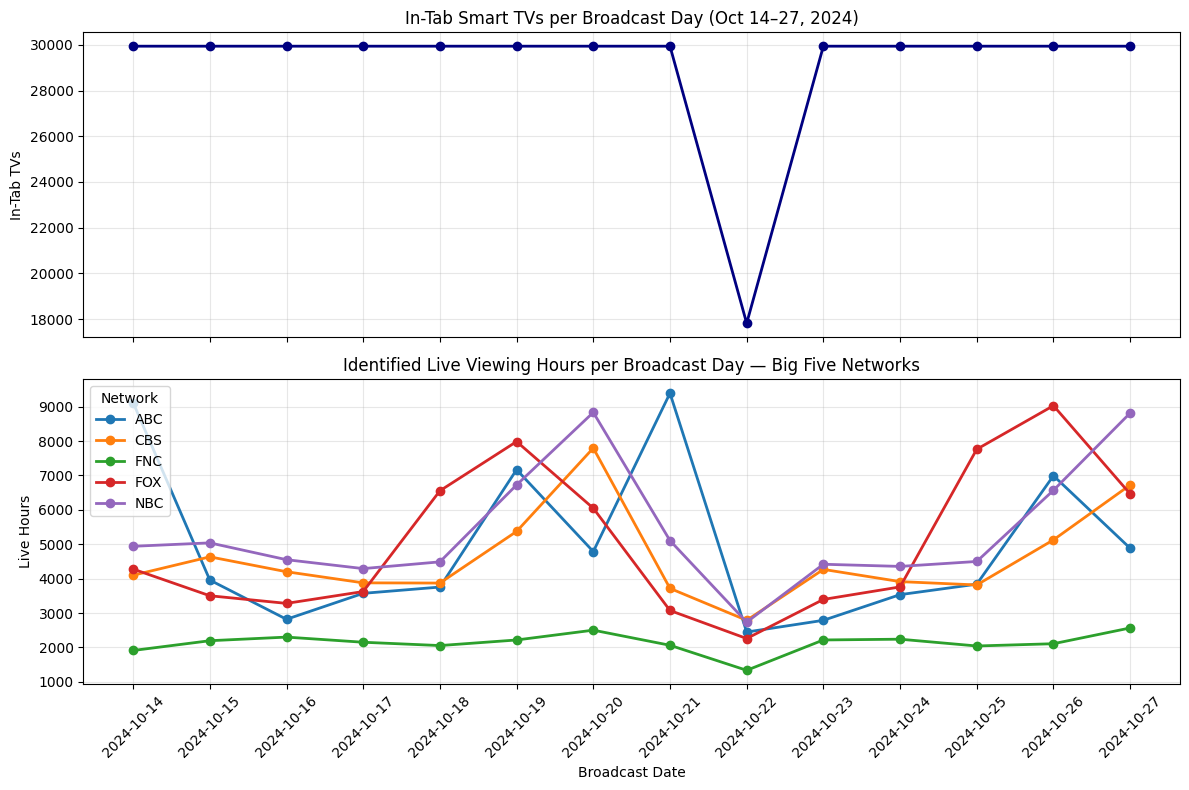

In [53]:
big_five = ['ABC', 'CBS', 'FNC', 'FOX', 'NBC']

daily_intab = acr_clean.groupby('broadcast_date')['tv_id'].nunique().reset_index(name='intab_tvs')

daily_big5 = (
    acr_clean[
        (acr_clean['session_type'] == 'live') &
        (acr_clean['network_code'].isin(big_five))
    ]
    .groupby(['broadcast_date', 'network_code'])['duration_hr']
    .sum()
    .unstack(fill_value=0.0)
)

# plot: TVs in-tab per day; live hours per day for the big five networks
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(daily_intab['broadcast_date'], daily_intab['intab_tvs'], marker='o', linewidth=2, color='navy')
axes[0].set_title('In-Tab Smart TVs per Broadcast Day (Oct 14–27, 2024)')
axes[0].set_ylabel('In-Tab TVs')
axes[0].grid(True, alpha=0.3)

for net in big_five:
    if net in daily_big5.columns:
        axes[1].plot(daily_big5.index, daily_big5[net], marker='o', linewidth=2, label=net)

axes[1].set_title('Identified Live Viewing Hours per Broadcast Day — Big Five Networks')
axes[1].set_xlabel('Broadcast Date')
axes[1].set_ylabel('Live Hours')
axes[1].legend(title='Network')
axes[1].grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Task 4.2 - Spike and broken day

In [54]:
# Biggest spike: network and broadcast day with the most identified live hours
daily_net_live = (
    acr_clean[acr_clean['session_type'] == 'live']
    .groupby(['broadcast_date', 'network_code'])['duration_hr']
    .sum()
    .reset_index()
    .sort_values('duration_hr', ascending=False)
    .reset_index(drop=True)
)
top_spike = daily_net_live.iloc[0]
spike_date = str(top_spike['broadcast_date'])
spike_net = str(top_spike['network_code'])

# Broken day: check daily anomalies in in-tab TVs, live hours per in-tab TV, or unknown share
daily_diag = acr_clean.groupby('broadcast_date').agg(
    intab_tvs=('tv_id', 'nunique'),
    total_hours=('duration_hr', 'sum'),
    live_hours=('duration_hr', lambda s: s[acr_clean.loc[s.index, 'session_type'] == 'live'].sum()),
    unknown_hours=('duration_hr', lambda s: s[acr_clean.loc[s.index, 'session_type'] == 'unknown'].sum()),
    sessions=('session_id', 'count')
).reset_index()
daily_diag['hours_per_intab_tv'] = daily_diag['total_hours'] / daily_diag['intab_tvs']
daily_diag['live_hours_per_intab_tv'] = daily_diag['live_hours'] / daily_diag['intab_tvs']
daily_diag['unknown_share'] = daily_diag['unknown_hours'] / daily_diag['total_hours']

# Identify the most anomalous day (z-score across key integrity metrics)
for col in ['intab_tvs', 'hours_per_intab_tv', 'live_hours_per_intab_tv', 'unknown_share']:
    med = daily_diag[col].median()
    mad = (daily_diag[col] - med).abs().median()
    daily_diag[f'z_{col}'] = (daily_diag[col] - med).abs() / (mad if mad > 0 else 1.0)

daily_diag['max_anomaly_score'] = daily_diag[['z_intab_tvs', 'z_hours_per_intab_tv', 'z_live_hours_per_intab_tv', 'z_unknown_share']].max(axis=1)
broken_day_date = str(daily_diag.sort_values('max_anomaly_score', ascending=False).iloc[0]['broadcast_date'])

print("Biggest spike (date, network):", f"{spike_date}, {spike_net}")
print("Broken day (date):", broken_day_date)

Biggest spike (date, network): 2024-10-21, ABC
Broken day (date): 2024-10-22


**Answer:**
Biggest spike (`2024-10-21, ABC` — `9,392.46` live hours): Looking at `programs`, `NFL Football` (Monday Night Football) aired on ABC from `20:15` to `23:25` Eastern (`telecast_id = 1000283`), driving a massive primetime live-viewing surge. (Similar genuine audience spikes occur on `2024-10-14` on ABC for Monday Night Football with `9,117.65` hours, `2024-10-26` on FOX for World Series Game 2 with `9,030.21` hours, and Sundays `2024-10-20` and `2024-10-27` on NBC for Sunday Night Football with `8,833.79` and `8,815.71` hours).

Broken day (`2024-10-22`): On every other broadcast day, all `29,940` TVs are in-tab, but on `2024-10-22` the number of in-tab TVs suddenly plunges by 40.5% to `17,818` TVs (and total live hours drop proportionally from ~`42,300` to `25,107.75`). However, viewing per in-tab TV did not change at all: total hours per in-tab TV (`4.45` hrs), live hours per in-tab TV (`1.41` hrs), and the unknown share (`0.393`) on Oct 22 are identical to normal weekdays (`4.44–4.46` total hrs and `1.41` live hrs on Oct 15–16 and Oct 23). This proves that audience behavior was normal, and a data collection / ingestion failure caused ~40.5% of TVs (`12,122` devices) to drop out completely on that day.

How it distorts metrics & whether to drop, fix, or flag:
* If nobody noticed, daily volume totals (total hours, viewing TV counts, reach) on `2024-10-22` would appear to crash by ~40.5% across every network simultaneously, and any telecast rating using a 2-week average in-tab denominator (`29,074.1`) instead of that day's in-tab TVs (`17,818`) would be understated by ~40%. Even with a daily in-tab denominator (`17,818`), if the missing devices dropped out non-randomly (e.g., an outage in specific DMAs or ISPs), that day's ratings would be geographically biased.
* Action — Flag (and fix/re-weight rather than blindly use raw totals, or drop from unadjusted volume trends): The day should be flagged as a partial feed outage. Because per-in-tab-TV behavior (`4.45` total hrs, `1.41` live hrs) is intact, we do not need to throw away the `17,818` valid TVs for rate/rating calculations if we use the day's own in-tab denominator (`17,818`) and fix any regional/demographic dropout via daily calibration weights (Lab 4), while excluding or scaling raw Oct 22 volume totals so they do not fake a 40% audience drop.

## Task 5.1 - Sampling error vs bias

In [55]:
# Panel in-tab households (H) per broadcast day
panel_intab_h_by_day = (
    dw_oct14_27[dw_oct14_27['resp_type'] == 'H']
    .groupby('b_date')['respondent_id']
    .nunique()
    .to_dict()
)

# 1021823: Sunday Night Football (NFL Football, NBC, Oct 27)
# 1012442: Hannity (FNC, Oct 16)
# 1016852: Unsellable Houses (HGTV, Oct 16)
target_ids = [1021823, 1012442, 1016852]
se_rows = []

for t_id in target_ids:
    row = ratings_df[ratings_df['telecast_id'] == t_id].iloc[0]
    p = row['_ref_r_exact'] / 100.0
    b_date = row['broadcast_date']
    n_fp = row['_n_intab_tv']
    n_pan = panel_intab_h_by_day.get(b_date, 0)
    
    se_fp = np.sqrt(p * (1.0 - p) / n_fp) * 100.0
    se_pan = np.sqrt(p * (1.0 - p) / n_pan) * 100.0
    gap = row['_tv_r_exact'] - row['_ref_r_exact']
    
    label = "Sunday Night Football" if t_id == 1021823 else row['program_name']
    se_rows.append({
        'telecast': f"{label} ({row['network_code']}, {b_date})",
        'SE_footprint': round(se_fp, 2),
        'SE_panel': round(se_pan, 2),
        'TVs_rating_minus_reference': round(gap, 1)
    })

se_table = pd.DataFrame(se_rows)
# table: telecast, SE footprint, SE panel, TVs' rating - reference
display(se_table)

,telecast,SE_footprint,SE_panel,TVs_rating_minus_reference
0,"Sunday Night Football (NBC, 2024-10-27)",0.27,0.75,-11.9
1,"Hannity (FNC, 2024-10-16)",0.09,0.24,-1.5
2,"Unsellable Houses (HGTV, 2024-10-16)",0.11,0.30,-1.6


**Answer:** With `29,940` in-tab TVs versus ~`3,874` in-tab panel households, the smart-TV footprint's sampling error ($SE$) is about `2.78×` smaller (~64% smaller) than the panel's:
* Sunday Night Football (`NBC, 2024-10-27`): $SE_{\text{footprint}} = \mathbf{0.27}$ pts vs. $SE_{\text{panel}} = \mathbf{0.76}$ pts, while the rating gap ($\text{TVs} - \text{reference}$) is `-11.9` pts (`21.2` vs. `33.1`).
* Hannity (`FNC, 2024-10-16`): $SE_{\text{footprint}} = \mathbf{0.09}$ pts vs. $SE_{\text{panel}} = \mathbf{0.24}$ pts, while the rating gap is `-1.5` pts (`0.8` vs. `2.3`).
* Unsellable Houses (`HGTV, 2024-10-16`): $SE_{\text{footprint}} = \mathbf{0.11}$ pts vs. $SE_{\text{panel}} = \mathbf{0.30}$ pts, while the rating gap is `-1.6` pts (`2.1` vs. `3.7`).

Which error is bigger, and does more data shrink it?
Systematic bias (the gap between the TVs' rating and the reference: `-11.9`, `-1.5`, and `-1.6` rating points) is vastly bigger — roughly 15 to 44 times larger than the footprint's sampling error (`0.09–0.27` points). Adding more unweighted smart TVs does NOT shrink this bias at all: more data only shrinks random sampling error ($SE \propto 1/\sqrt{n}$), meaning a larger convenience sample simply gives a more precise estimate of the wrong (biased) number ("big is not the same as representative").

## Task 5.2 - Answer to the planner

**Answer:** From the raw smart-TV ACR feed, the unweighted percentage of in-tab TVs that watched Sunday Night Football (Dallas at San Francisco, NBC, October 27) is 21.2%, whereas the true currency household rating is 33.1% (a `-11.9` point undercount). We cannot present `21.2` as a household rating tomorrow because this dataset measures individual opted-in TV screens rather than representative US households. Specifically, this feed cannot see people in the room (age/sex demographics or co-viewing), other TV sets in the same home (US homes average ~2.6 sets, but we only track one set per home), unrecognized viewing on streaming apps or unindexed feeds (which account for 39.6% `unknown` and 25.7% `app` hours), or households that opted out, do not own this TV brand, or failed IP matching (34.8% of TVs could not be matched 1-to-1 via hashed IP). Moreover, the matched footprint is heavily skewed toward high-income (`$100k+` index `120.1`) and Western (`index 110.4`) homes while under-representing `<$50k` homes (`index 71.8`) and older viewers. Before using this feed for client planning, we need statistical weighting/calibration against a representative panel to correct for demographic skew, a multi-set/in-home coverage adjustment, and person-level modeling (VPVH) to convert device tuning into currency-grade household and person ratings.

## Bonus

In [56]:
# Identify A25-54 persons (R and L): attr_id 325 (25-34), 335 (35-49), 350 (50-54)
a25_54_ids = set(
    viewer_attributes.loc[
        viewer_attributes['attr_id'].isin([325, 335, 350]),
        'respondent_id'
    ]
)

# Sunday Night Football telecast on NBC, 2024-10-27 (telecast_id = 1021823)
snf_id = 1021823
snf_row = ratings_df[ratings_df['telecast_id'] == snf_id].iloc[0]
snf_prog = prog[prog['telecast_id'] == snf_id].iloc[0]
snf_start = snf_prog['start_ts']
snf_end = snf_prog['end_ts']
snf_net = snf_prog['network_code']
snf_date = '2024-10-27'

# Filter Lab 1 viewings on 2024-10-27 on NBC overlapping SNF by >= 60 seconds
vw_all = viewings.copy()
vw_all['start_ts'] = pd.to_datetime(vw_all['start_ts'])
vw_all['end_ts'] = pd.to_datetime(vw_all['end_ts'])
if vw_all['start_ts'].dt.tz is not None:
    vw_all['start_ts'] = vw_all['start_ts'].dt.tz_convert('America/New_York').dt.tz_localize(None)
    vw_all['end_ts'] = vw_all['end_ts'].dt.tz_convert('America/New_York').dt.tz_localize(None)

vw_snf_cand = vw_all[
    (vw_all['network_code'] == snf_net) &
    (vw_all['start_ts'] < snf_end) &
    (vw_all['end_ts'] > snf_start)
].copy()

vw_snf_cand['overlap_sec'] = (
    np.minimum(vw_snf_cand['end_ts'], snf_end) - np.maximum(vw_snf_cand['start_ts'], snf_start)
).dt.total_seconds()

vw_snf_watchers = vw_snf_cand[vw_snf_cand['overlap_sec'] >= 60].drop_duplicates(subset=['respondent_id']).copy()

# Day's weights from daily_weights on 2024-10-27
dw_snf = dw_temp[dw_temp['b_date'] == snf_date].copy()
day_weight_map = dw_snf.set_index('respondent_id')['weight'].to_dict()
vw_snf_watchers['day_weight'] = vw_snf_watchers['respondent_id'].map(day_weight_map).fillna(vw_snf_watchers['weight'])

# Weighted A25-54 persons (R and L) who watched ÷ Weighted households (H) that watched
watched_a25_54_weight = vw_snf_watchers[
    vw_snf_watchers['resp_type'].isin(['R', 'L']) &
    vw_snf_watchers['respondent_id'].isin(a25_54_ids)
]['day_weight'].sum()

watched_hh_weight = vw_snf_watchers[vw_snf_watchers['resp_type'] == 'H']['day_weight'].sum()

vpvh_a25_54 = watched_a25_54_weight / watched_hh_weight

# Universes from the panel's weights on that day
us_tv_hh_univ = dw_snf[dw_snf['resp_type'] == 'H']['weight'].sum()
us_a25_54_univ = dw_snf[
    dw_snf['resp_type'].isin(['R', 'L']) &
    dw_snf['respondent_id'].isin(a25_54_ids)
]['weight'].sum()

# A25-54 rating = TVs' household rating * VPVH * (US TV households / US A25-54 persons)
a25_54_rating = snf_row['_tv_r_exact'] * vpvh_a25_54 * (us_tv_hh_univ / us_a25_54_univ)

print("VPVH A25-54:", f"{vpvh_a25_54:.3f}")
print("A25-54 rating (persons):", f"{a25_54_rating:.1f}")

VPVH A25-54: 0.513
A25-54 rating (persons): 11.1


**Answer:** Applying the Lab 1 panel's weighted A25–54 viewers-per-viewing-household ratio (VPVH) for Sunday Night Football directly to the smart-TV household rating assumes:
1. Identical household composition and co-viewing behavior (VPVH invariance): It assumes that a viewing smart-TV household in the vendor's footprint has the exact same average number of A25–54 viewers watching the game together in front of the set as a representative viewing household in the US panel (ignoring the fact that the ACR footprint skews wealthier and younger/middle-aged, and only observes one screen rather than all sets in the home).
2. Unbiased household rating Input: Because the formula multiplies the raw smart-TV household rating (`21.2`) by the panel's VPVH and universe ratio, it assumes the smart-TV household rating itself is a valid measure of household reach — otherwise, the ~36% downward bias in the unweighted smart-TV household rating (`21.2` vs. `33.1` reference) is carried directly into the estimated A25–54 person rating unless the household rating is calibrated/weighted first.